# 1. Open datasets

In [3]:
%conda install -c conda-forge llvmlite numba -y

Channels:
 - conda-forge
 - defaults
Platform: osx-64
Solving environment: done

## Package Plan ##

  environment location: /Users/erin.so/miniforge3/envs/chemiinfo

  added / updated specs:
    - llvmlite
    - numba


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |       8_kmp_llvm           8 KB  conda-forge
    libblas-3.11.0             |11_he492b99_openblas          18 KB  conda-forge
    libcblas-3.11.0            |11_h9b27e0a_openblas          18 KB  conda-forge
    libgcc-16.2.0              |       h13771c8_7         382 KB  conda-forge
    libgfortran-16.2.0         |       h7e5c614_7          98 KB  conda-forge
    libgfortran5-16.2.0        |       h2539e6c_7        1000 KB  conda-forge
    liblapack-3.11.0           |11_h859234e_openblas          18 KB  conda-forge
    libopenblas-0.3.34         |openmp_h9e49c7b_1         6.0 MB  conda-forge
  

In [1]:
%pip install -r ../requirements.txt -v

Using pip 26.2.1 from /Users/erin.so/miniforge3/envs/chemiinfo/lib/python3.11/site-packages/pip (python 3.11)
  Using cached pytdc-1.1.15-py3-none-any.whl
  Obtaining dependency information for pandas from https://files.pythonhosted.org/packages/7d/48/88e8d250d28efa8163294f6809a71683c7ee67f63ac7c33021c0503b3547/pandas-3.0.6-cp311-cp311-macosx_10_9_x86_64.whl.metadata
  Using cached pandas-3.0.6-cp311-cp311-macosx_10_9_x86_64.whl.metadata (79 kB)
  Obtaining dependency information for rdkit from https://files.pythonhosted.org/packages/b1/19/4a606ef1c090b0abc54627a4aa5313c8bbef50da888841101bf1aa89ff70/rdkit-2025.9.3-cp311-cp311-macosx_10_15_x86_64.whl.metadata
  Using cached rdkit-2025.9.3-cp311-cp311-macosx_10_15_x86_64.whl.metadata (4.2 kB)
  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/79/67/1904bf57ab9ea77b5ba3899178bcb35ff8d814fc38ef6d1283bcddeaf04a/scikit_learn-1.9.1-cp311-cp311-macosx_10_9_x86_64.whl.metadata
  Using cached scikit_

In [4]:
from pathlib import Path

from tdc.single_pred import ADME, Tox
import pandas as pd

# Save datasets in the project-level data/raw directory
raw_dir = Path("../data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

# Load regression dataset
solubility = ADME(name="Solubility_AqSolDB")
df_reg = solubility.get_data()
df_reg.to_csv(raw_dir / "solubility_aqsoldb.tab", sep="\t", index=False)

# Load classification dataset
herg = Tox(name="hERG")
df_clf = herg.get_data()
df_clf.to_csv(raw_dir / "herg.tab", sep="\t", index=False)

# Preview datasets and report shapes
display(df_reg.head(10))
display(df_clf.head(10))
print("Regression:", df_reg.shape)
print("Classification:", df_clf.shape)

Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!


,Drug_ID,Drug,Y
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065
5,vinyltoluene,C=Cc1cccc(C)c1,-3.123150
6,3-(3-ethylcyclopentyl)propanoic acid,CCC1CCC(CCC(=O)O)C1,-3.286116
7,"11,16,17,21-tetrahydroxypregna-1,4-diene-3,20-...",CC12C=CC(=O)C=C1CCC1C2C(O)CC2(C)C1CC(O)C2(O)C(...,-2.664549
8,bis(4-fluorophenyl)methanone,O=C(c1ccc(F)cc1)c1ccc(F)cc1,-4.396652
9,1-[2-(benzoyloxy)propoxy]propan-2-yl benzoate ...,O=C(OCCCOCCCOC(=O)c1ccccc1)c1ccccc1,-4.595503


,Drug_ID,Drug,Y
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0
5,BENPERIDOL,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F)cc1,1.0
6,NaN,Fc1ccc(-n2cc(C3CCN(CCN4CCNC4=S)CC3)c3ccccc32)cc1,1.0
7,BMCL20031829_03,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccccc23)CC1,1.0
8,VANOXERINE HYDROCHLORIDE,Fc1ccc(C(OCCN2CCN(CCCc3ccccc3)CC2)c2ccc(F)cc2)cc1,1.0
9,L-691121,CS(=O)(=O)Nc1ccc2c(c1)C(=O)CC1(CCN(CCc3ccc4non...,1.0


Regression: (9982, 3)
Classification: (655, 3)


# 2. Check for missing or invalid values

In [5]:
import numpy as np, pandas as pd

In [6]:
df_reg = solubility.get_data()

df_reg = df_reg.rename(columns={
    "Drug": "SMILES",
    "Y": "Solubility"
})

print("Dataset: Solubility_AqSolDB")
print("Target: Aqueous solubility")
print("Original rows:", len(df_reg))


print("Missing SMILES:", df_reg["SMILES"].isna().sum())
print("Missing solubility:", df_reg["Solubility"].isna().sum())

df_clf = herg.get_data()

df_clf = df_clf.rename(columns={
    "Drug": "SMILES",
    "Y": "HerG"
})

print("Dataset: HerG")
print("Target: Toxicity")
print("Original rows:", len(df_clf))


print("Missing SMILES:", df_clf["SMILES"].isna().sum())
print("Missing HerG:", df_clf["HerG"].isna().sum())

Dataset: Solubility_AqSolDB
Target: Aqueous solubility
Original rows: 9982
Missing SMILES: 0
Missing solubility: 0
Dataset: HerG
Target: Toxicity
Original rows: 655
Missing SMILES: 0
Missing HerG: 0


In [ ]:
initial_rows = len(df_reg)

df_reg = df_reg.dropna(subset=["SMILES", "Solubility"]).copy()

print("Rows removed:", initial_rows - len(df_reg))
print("Rows remaining:", len(df_reg))
display (df_reg.head())

initial_rows = len(df_clf)

df_clf = df_clf.dropna(subset=["SMILES", "HerG"]).copy()

print("Rows removed:", initial_rows - len(df_clf))
print("Rows remaining:", len(df_clf))
display (df_clf.head())

Rows removed: 0
Rows remaining: 9982


,Drug_ID,SMILES,Solubility
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065


Rows removed: 0
Rows remaining: 655


,Drug_ID,SMILES,HerG
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0


# 3. Check for the SMILES 

In [9]:
import rdkit 
from rdkit import Chem

# Set the column names
smiles_col = 'smiles'
target_col = 'HerG'  
# Check the target values
print("Target distribution:")
print(df_clf[target_col].value_counts(dropna=False))

# Count missing targets and SMILES
print("Missing targets:", df_clf[target_col].isna().sum())
smiles_col = "SMILES"

# Remove rows with missing targets
df_clf = df_clf.dropna(subset=[target_col]).copy()

print("Rows after removing missing targets:", len(df_clf))

Target distribution:
HerG
1.0    451
0.0    204
Name: count, dtype: int64
Missing targets: 0
Rows after removing missing targets: 655


# 4. Create a molecule column and check invalid SMILES

In [10]:
# Convert SMILES into molecule objects
df_clf['Molecule'] = df_clf[smiles_col].apply(
    lambda x: Chem.MolFromSmiles(x) if isinstance(x, str) else None
)

# Count invalid SMILES
invalid_smiles = df_clf['Molecule'].isna().sum()
print("Invalid SMILES:", invalid_smiles)

# Remove invalid SMILES
df_clf = df_clf.dropna(subset=['Molecule']).copy()

print("Rows after removing invalid SMILES:", len(df_clf))

Invalid SMILES: 0
Rows after removing invalid SMILES: 655


[18:07:56] WARNING: not removing hydrogen atom without neighbors
[18:07:56] WARNING: not removing hydrogen atom without neighbors


# 5. Generate canonical SMILES

In [11]:
# Function to canonicalize SMILES
def canonicalize_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        canonical_smiles = Chem.MolToSmiles(mol, canonical=True)
        return canonical_smiles
    else:
        return None

# Apply the function to the dataset
df_clf['canonical_smiles'] = df_clf[smiles_col].apply(canonicalize_smiles)

df_clf.head()

[18:08:02] WARNING: not removing hydrogen atom without neighbors
[18:08:02] WARNING: not removing hydrogen atom without neighbors


,Drug_ID,SMILES,HerG,Molecule,canonical_smiles
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0,<rdkit.Chem.rdchem.Mol object at 0x12a132880>,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0,<rdkit.Chem.rdchem.Mol object at 0x12a132b20>,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0,<rdkit.Chem.rdchem.Mol object at 0x12a1325e0>,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0,<rdkit.Chem.rdchem.Mol object at 0x12a132110>,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0,<rdkit.Chem.rdchem.Mol object at 0x12a132b90>,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...


# 6. Identify duplicates and conflicting targets

In [12]:
# Count duplicate structures
print("Duplicate structures:", df_clf['canonical_smiles'].duplicated().sum())

# Find structures with different target values
target_counts = df_clf.groupby('canonical_smiles')[target_col].nunique()

conflicting_smiles = target_counts[target_counts > 1].index

print("Structures with conflicting targets:", len(conflicting_smiles))

Duplicate structures: 7
Structures with conflicting targets: 3


# 7. Plot the target distribution

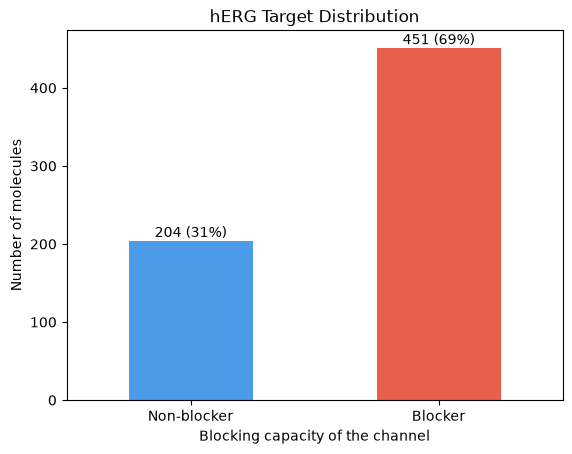

In [15]:
import matplotlib.pyplot as plt

palette = {0.0: '#4C9BE8', 1.0: '#E8604C'}

counts = df_clf[target_col].value_counts().sort_index()
ax = counts.plot(kind='bar', color=[palette[0.0], palette[1.0]])

# Show count and percentage above each bar
for i, v in enumerate(counts):
    ax.text(i, v + 5, f'{v} ({v/counts.sum():.0%})', ha='center')

plt.xticks([0, 1], ['Non-blocker', 'Blocker'], rotation=0)
plt.xlabel('Blocking capacity of the channel')
plt.ylabel('Number of molecules')
plt.title('hERG Target Distribution')
plt.show()